# MIT Academy of Engineering, Alandi, Pune
# Practical No. 04: Image Generation using Deep Convolutional GAN (DCGAN)
## Department of CSE (AI & ML)
### Class: T.Y.Tech
### Course: Generative AI Lab

---



## Student Information
- **Name of Student:** Sakshi Uttam Walunj
- **PRN Number:** 202502110007
- **Batch:** A3
- **Date of Submission:** 21-10-2026

## General Instructions
- The notebook presents the dataset, DCGAN architecture, adversarial training process, generated samples, and evaluation results in a structured sequence.

## 1. Objective
Implement and train a Deep Convolutional Generative Adversarial Network (DCGAN) on CIFAR-10, generate synthetic images, and evaluate performance by examining Generator and Discriminator loss curves and the visual quality of generated images.

## 2. Problem Definition

- **Dataset:** CIFAR-10, a standard image dataset containing 32 × 32 RGB images across 10 object classes.
- **Task:** Train a DCGAN to learn visual patterns from real CIFAR-10 images and generate new synthetic images resembling the training data.
- **Evaluation:** Inspect generated image grids and analyze the Generator and Discriminator loss curves over training epochs.

## 3. Methodology

### Network architecture
- **Generator:** Converts a random latent vector into a 32 × 32 RGB image using a dense layer and transposed convolution layers.
- **Discriminator:** Uses convolution layers to distinguish real CIFAR-10 images from generated images.
- **Activation functions:** Leaky ReLU in hidden layers and `tanh` at the Generator output.
- **Loss function:** Binary cross-entropy with logits.
- **Optimization:** Adam optimizer with learning rate 0.0002 and beta₁ = 0.5.

### Training process
1. Normalize real images to the range [-1, 1].
2. Generate random latent vectors and produce fake images.
3. Train the Discriminator on real images and generated images.
4. Train the Generator to make generated images more likely to be classified as real.
5. Record both losses, display sample images, and plot the loss curves.

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

SEED = 42
tf.keras.utils.set_random_seed(SEED)

LATENT_DIM = 100
BATCH_SIZE = 128
EPOCHS = 20          # Increase to 50–100 for better results if time/GPU permits
TRAIN_LIMIT = 20000  # Set to None to use all 50,000 training images
OUTPUT_DIR = "dcgan_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TensorFlow version: 2.21.0
GPU devices: []


## 2. Load and prepare CIFAR-10

### Dataset Loading and Preprocessing
This cell downloads or loads CIFAR-10, which contains small colour images. The training images are converted to `float32` and scaled from pixel values 0–255 to the range [-1, 1]. This matches the Generator's `tanh` output and helps keep the real and generated images on compatible scales. The cell also displays a grid of real examples so the dataset can be inspected before training.

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2248s 13us/step
Training image shape: (20000, 32, 32, 3)
Pixel range: -1.0 to 1.0
Test image shape: (10000, 32, 32, 3)


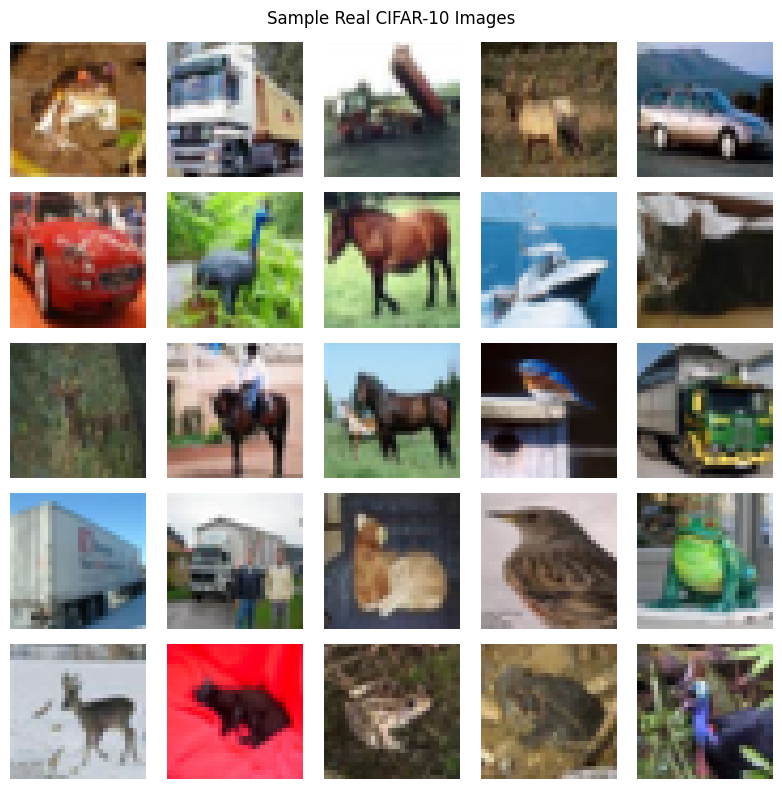

In [2]:
(x_train, _), (x_test, _) = tf.keras.datasets.cifar10.load_data()

if TRAIN_LIMIT is not None:
    x_train = x_train[:TRAIN_LIMIT]

# DCGAN generator uses tanh, so normalize real images to [-1, 1].
x_train = (x_train.astype("float32") - 127.5) / 127.5

print("Training image shape:", x_train.shape)
print("Pixel range:", float(x_train.min()), "to", float(x_train.max()))
print("Test image shape:", x_test.shape)

# Show sample real images
plt.figure(figsize=(8, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    image = ((x_train[i] + 1.0) * 127.5).clip(0, 255).astype("uint8")
    plt.imshow(image)
    plt.axis("off")
plt.suptitle("Sample Real CIFAR-10 Images")
plt.tight_layout()
plt.show()

## 3. Create the input pipeline

### Data Pipeline Preparation
The dataset pipeline shuffles the training examples so the model does not see them in the same order every epoch. Batching groups images into manageable sets, and prefetching allows TensorFlow to prepare upcoming batches while the current batch is processed. `drop_remainder=True` keeps each batch the same size.

In [3]:
dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(min(len(x_train), 10000), seed=SEED, reshuffle_each_iteration=True)
dataset = dataset.batch(BATCH_SIZE, drop_remainder=True)
dataset = dataset.prefetch(tf.data.AUTOTUNE)

print("Batches per epoch:", len(x_train) // BATCH_SIZE)

Batches per epoch: 156


## 4. Define the Generator

### Generator Architecture
The Generator receives a 100-dimensional random vector and gradually transforms it into a 32 × 32 RGB image. A dense layer first expands the vector into a small feature map. Transposed convolution layers then increase the spatial dimensions from 4 × 4 to 8 × 8, 16 × 16, and finally 32 × 32. Batch normalization helps stabilize learning, Leaky ReLU adds non-linearity, and `tanh` produces output pixels in [-1, 1].

In [4]:
def build_generator(latent_dim=LATENT_DIM):
    model = tf.keras.Sequential(name="Generator")
    model.add(layers.Input(shape=(latent_dim,)))
    model.add(layers.Dense(4 * 4 * 256, use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Reshape((4, 4, 256)))

    model.add(layers.Conv2DTranspose(128, 4, strides=2, padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(negative_slope=0.2))

    model.add(layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(negative_slope=0.2))

    model.add(layers.Conv2DTranspose(3, 4, strides=2, padding="same", activation="tanh"))
    return model

generator = build_generator()
generator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4096)           │       409,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 4096)           │        16,384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 128)      │       524,288 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 3)      │         3,075 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,085,187 (4.14 MB)

 Trainable params: 1,076,611 (4.11 MB)

 Non-trainable params: 8,576 (33.50 KB)

## 5. Define the Discriminator

### Discriminator Architecture
The Discriminator takes a 32 × 32 RGB image and predicts whether it is real or generated. Convolution layers reduce the spatial dimensions while learning image features. Leaky ReLU provides non-linear activation, and dropout helps reduce overfitting. The final dense layer returns one logit rather than a probability; the binary cross-entropy loss below is configured to accept logits.

In [5]:
def build_discriminator():
    model = tf.keras.Sequential(name="Discriminator")
    model.add(layers.Input(shape=(32, 32, 3)))
    model.add(layers.Conv2D(64, 4, strides=2, padding="same"))
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(128, 4, strides=2, padding="same"))
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(256, 4, strides=2, padding="same"))
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    # Output is a logit; sigmoid is applied by the loss function.
    model.add(layers.Dense(1))
    return model

discriminator = build_discriminator()
discriminator.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 16, 16, 64)     │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 662,977 (2.53 MB)

 Trainable params: 662,977 (2.53 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Set up losses and optimizers

### Loss Functions and Optimization
Binary cross-entropy measures how well the networks meet their adversarial objectives. The Discriminator is trained to assign high scores to real images and low scores to generated images. The Generator is trained to make the Discriminator classify generated images as real. Adam updates the model weights using gradients, with a learning rate of 0.0002 and `beta_1=0.5`, common starting settings for DCGANs. Fixed random vectors are used to compare generated samples across epochs.

In [6]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_logits, fake_logits):
    real_loss = cross_entropy(tf.ones_like(real_logits), real_logits)
    fake_loss = cross_entropy(tf.zeros_like(fake_logits), fake_logits)
    return real_loss + fake_loss

def generator_loss(fake_logits):
    return cross_entropy(tf.ones_like(fake_logits), fake_logits)

generator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)

# Fixed latent vectors make progress images comparable across epochs.
fixed_noise = tf.random.normal([25, LATENT_DIM])

## 7. Define one training step

### Adversarial Training Step
This function performs one adversarial training step. It creates random noise and passes it through the Generator to produce fake images. The Discriminator evaluates both a batch of real images and the fake images. TensorFlow's gradient tapes calculate gradients for each network's loss, and the two optimizers update their respective weights. The Generator and Discriminator are updated separately using their own trainable variables.

In [7]:
@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal([batch_size, LATENT_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_logits = discriminator(real_images, training=True)
        fake_logits = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_logits)
        disc_loss = discriminator_loss(real_logits, fake_logits)

    gen_gradients = gen_tape.gradient(gen_loss, generator.trainable_variables)
    disc_gradients = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gen_gradients, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(disc_gradients, discriminator.trainable_variables))

    return gen_loss, disc_loss

## 8. Helper function to display generated images

### Synthetic Image Visualization
This helper uses the same fixed noise vectors each time it is called. It asks the Generator to create 25 images, rescales their pixel values from [-1, 1] to [0, 1] for display, and arranges them in a 5 × 5 grid. Saving these grids at different epochs makes it easier to visually compare progress during training.

In [8]:
def show_generated_images(epoch, save=True):
    predictions = generator(fixed_noise, training=False)
    predictions = (predictions + 1.0) / 2.0

    plt.figure(figsize=(7, 7))
    for i in range(25):
        plt.subplot(5, 5, i + 1)
        plt.imshow(tf.clip_by_value(predictions[i], 0, 1))
        plt.axis("off")
    plt.suptitle(f"Generated CIFAR-10-like Images — Epoch {epoch}")
    plt.tight_layout()

    if save:
        path = os.path.join(OUTPUT_DIR, f"generated_epoch_{epoch:03d}.png")
        plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

## 9. Train the DCGAN and record losses

### DCGAN Training Process
The outer loop runs through the configured number of epochs, while the inner loop processes each training batch. For every batch, the training step returns Generator and Discriminator losses. The notebook averages these losses for each epoch, records the elapsed time, and prints the metrics. Generated-image grids are saved at selected epochs so visual quality can be compared over time.

Epoch 001/20 | Generator loss: 2.2045 | Discriminator loss: 0.5529 | Time: 273.9s


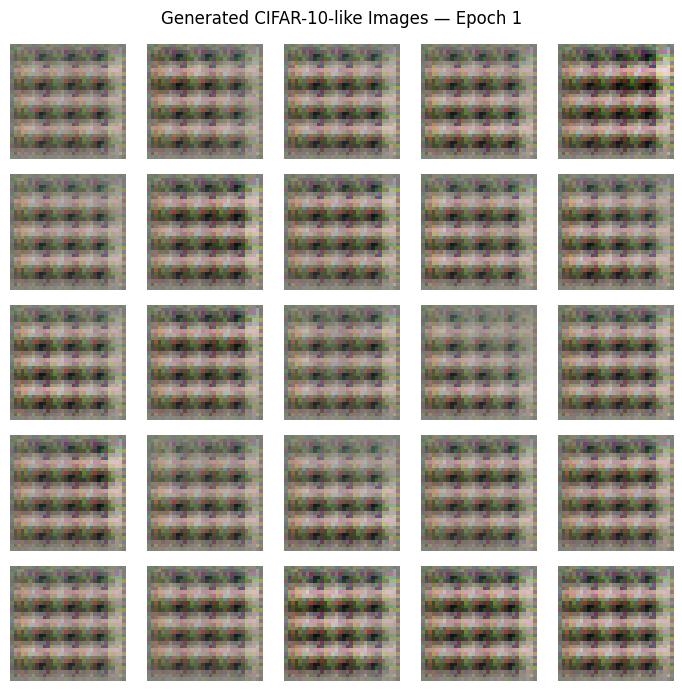

Epoch 002/20 | Generator loss: 1.5705 | Discriminator loss: 0.8772 | Time: 269.7s
Epoch 003/20 | Generator loss: 1.1977 | Discriminator loss: 1.0118 | Time: 273.6s
Epoch 004/20 | Generator loss: 1.0418 | Discriminator loss: 1.1098 | Time: 270.3s
Epoch 005/20 | Generator loss: 1.0068 | Discriminator loss: 1.1919 | Time: 270.0s


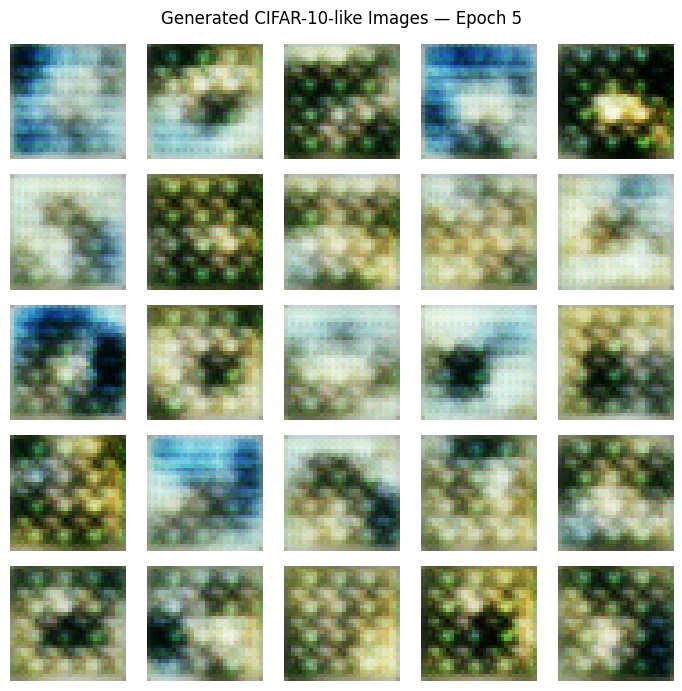

Epoch 006/20 | Generator loss: 0.8910 | Discriminator loss: 1.1812 | Time: 268.8s
Epoch 007/20 | Generator loss: 0.9006 | Discriminator loss: 1.2254 | Time: 270.3s
Epoch 008/20 | Generator loss: 0.9142 | Discriminator loss: 1.1889 | Time: 270.6s
Epoch 009/20 | Generator loss: 0.9430 | Discriminator loss: 1.1729 | Time: 321.9s
Epoch 010/20 | Generator loss: 0.9714 | Discriminator loss: 1.1483 | Time: 270.5s


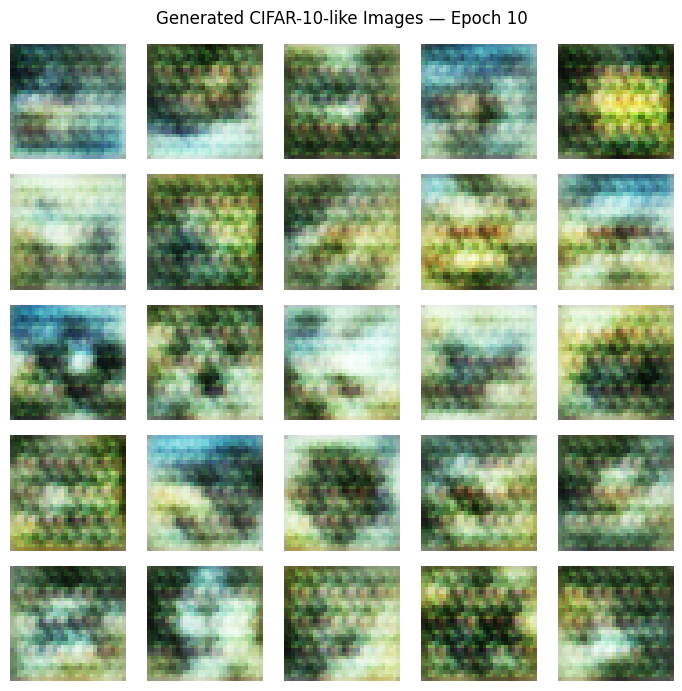

Epoch 011/20 | Generator loss: 1.0803 | Discriminator loss: 1.0776 | Time: 271.6s
Epoch 012/20 | Generator loss: 1.2520 | Discriminator loss: 0.9371 | Time: 272.1s
Epoch 013/20 | Generator loss: 1.2743 | Discriminator loss: 0.9189 | Time: 270.1s
Epoch 014/20 | Generator loss: 1.1655 | Discriminator loss: 1.0059 | Time: 321.9s
Epoch 015/20 | Generator loss: 1.2049 | Discriminator loss: 1.0230 | Time: 321.9s


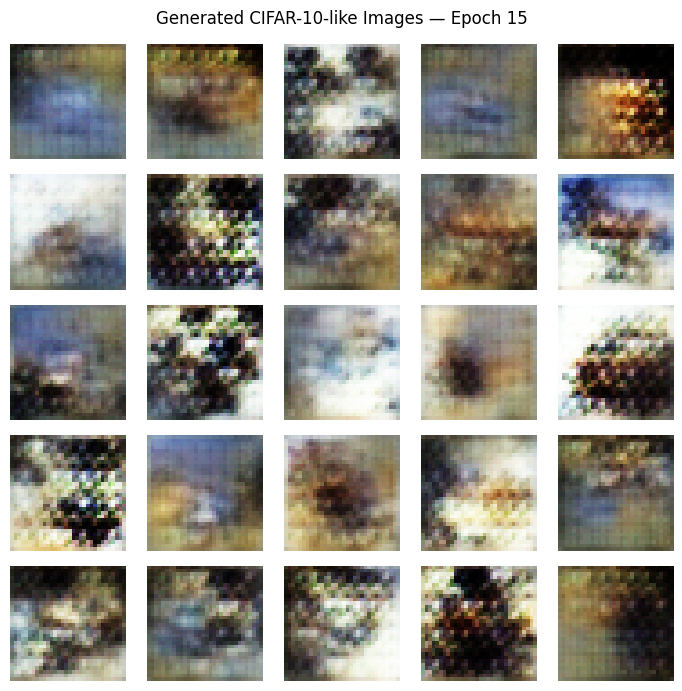

Epoch 016/20 | Generator loss: 1.0984 | Discriminator loss: 1.0742 | Time: 271.4s
Epoch 017/20 | Generator loss: 1.1641 | Discriminator loss: 1.0497 | Time: 270.0s
Epoch 018/20 | Generator loss: 1.1424 | Discriminator loss: 1.0683 | Time: 321.9s
Epoch 019/20 | Generator loss: 1.1603 | Discriminator loss: 1.0278 | Time: 270.2s
Epoch 020/20 | Generator loss: 1.1820 | Discriminator loss: 1.0438 | Time: 321.9s


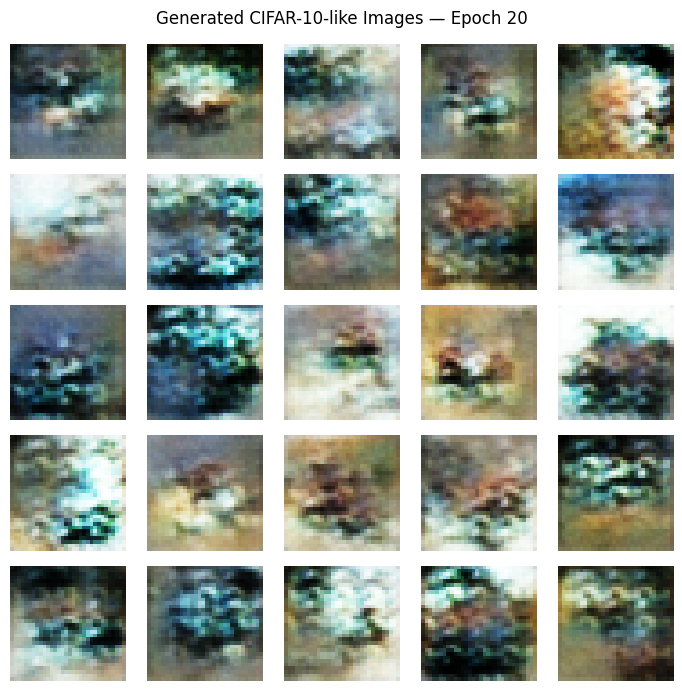

In [9]:
generator_losses = []
discriminator_losses = []
epoch_seconds = []

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()
    gen_batch_losses = []
    disc_batch_losses = []

    for real_batch in dataset:
        gen_loss, disc_loss = train_step(real_batch)
        gen_batch_losses.append(float(gen_loss.numpy()))
        disc_batch_losses.append(float(disc_loss.numpy()))

    mean_gen_loss = float(np.mean(gen_batch_losses))
    mean_disc_loss = float(np.mean(disc_batch_losses))
    elapsed = time.time() - start_time

    generator_losses.append(mean_gen_loss)
    discriminator_losses.append(mean_disc_loss)
    epoch_seconds.append(elapsed)

    print(
        f"Epoch {epoch:03d}/{EPOCHS} | "
        f"Generator loss: {mean_gen_loss:.4f} | "
        f"Discriminator loss: {mean_disc_loss:.4f} | "
        f"Time: {elapsed:.1f}s"
    )

    # Save a sample grid every 5 epochs and at the final epoch.
    if epoch % 5 == 0 or epoch == 1 or epoch == EPOCHS:
        show_generated_images(epoch)

## 10. Plot Generator and Discriminator loss curves

### Training Loss Analysis
This cell plots the average Generator and Discriminator losses against epoch number. The graph is saved to the output directory for the practical report. GAN losses often fluctuate because the two networks continuously compete, so the curves should be interpreted together with the generated images rather than assuming that both losses must decrease steadily.

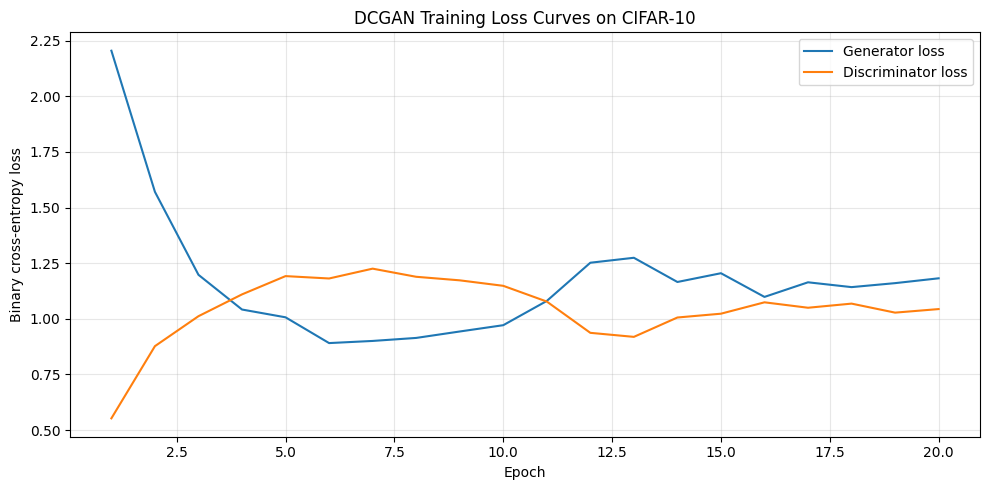

Saved loss plot to: dcgan_outputs/loss_curves.png


In [10]:
epochs_axis = np.arange(1, len(generator_losses) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs_axis, generator_losses, label="Generator loss")
plt.plot(epochs_axis, discriminator_losses, label="Discriminator loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("DCGAN Training Loss Curves on CIFAR-10")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
loss_plot_path = os.path.join(OUTPUT_DIR, "loss_curves.png")
plt.savefig(loss_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved loss plot to:", loss_plot_path)

## 11. Inspect final generated images

### Generated Image Evaluation
This cell generates and displays a final 5 × 5 grid using the trained Generator. Compare this grid with the real CIFAR-10 samples shown earlier. Record whether the outputs show recognizable colour patterns or object-like structures, whether images look diverse, and whether some samples are nearly identical.

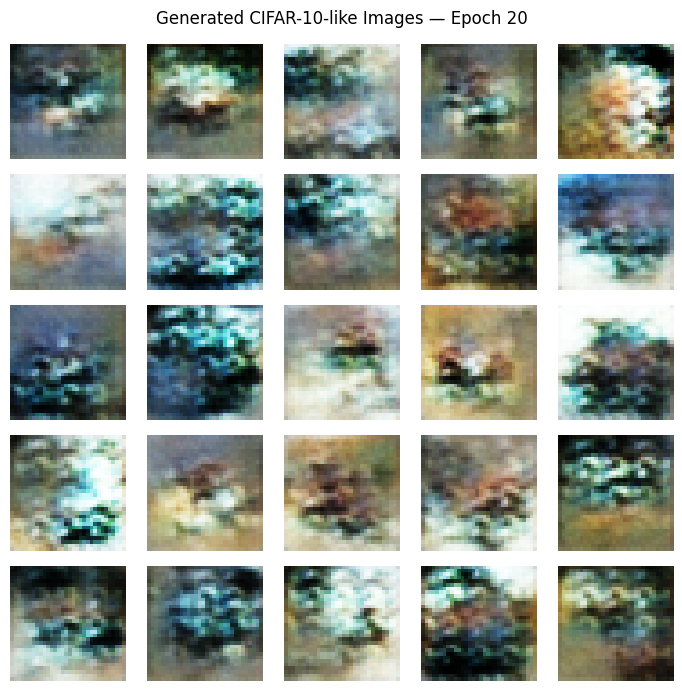

In [11]:
show_generated_images(EPOCHS, save=True)

## 12. Save trained models

### Saving Trained Models
This cell saves the trained Generator and Discriminator in Keras format. The Generator can later be loaded to create more synthetic images without retraining. The Discriminator is saved as well so the trained model components are both available for inspection or future experiments.

In [12]:
generator_path = os.path.join(OUTPUT_DIR, "dcgan_generator.keras")
discriminator_path = os.path.join(OUTPUT_DIR, "dcgan_discriminator.keras")

generator.save(generator_path)
discriminator.save(discriminator_path)

print("Generator saved to:", generator_path)
print("Discriminator saved to:", discriminator_path)

Generator saved to: dcgan_outputs/dcgan_generator.keras
Discriminator saved to: dcgan_outputs/dcgan_discriminator.keras


## 13. Evaluation and observations

The training results are summarized using the recorded loss values, loss curves, and generated image samples.

### Loss-curve analysis
- **Generator loss** measures how poorly the Generator fools the Discriminator. It may rise or fall during training; it does not need to decrease smoothly.
- **Discriminator loss** measures its classification error on real and generated images. It can fluctuate as the Generator improves.
- GAN losses do not behave like ordinary supervised-learning losses. A low loss for one network alone does not prove that the GAN is performing well.
- Look for unstable oscillations, a loss staying near an extreme, or image samples that stop improving. The two losses need to be interpreted together with the generated images.

### Generated-image quality
- At epoch 1, the outputs were nearly identical grid-like noise patterns.
- By epoch 20, the images were varied and colourful, with blue/teal, brown and white textures.
- No clear objects or recognizable shapes appear yet.
- The images show variety, so there was no mode collapse in the final output.

### Results table
The following table summarizes the evaluation criteria.

| Evaluation item | Your observation |
|---|---|
| Dataset and training images used | CIFAR-10, 20,000 training images (32×32 RGB), batch size 128 |
| Number of epochs completed | 20 |
| Final Generator loss | 1.1820 |
| Final Discriminator loss | 1.0438 |
| Visual quality of generated images | Colourful, blurry, texture-like images with no clear objects. Much better than epoch 1 |
| Training stability | Stable. Both losses settled around 1.0–1.2 with no collapse |

**Conclusion:** The DCGAN trained successfully for 20 epochs. Both losses stayed balanced, and the generated images improved from repeated noise patterns to varied, colourful images. They do not yet show recognizable objects.

## 14. Results and Discussion

The model is evaluated using the final losses, generated samples, and training stability.

- **Final Generator loss:** 1.1820
- **Final Discriminator loss:** 1.0438
- **Generated image quality:** At epoch 1, all images were nearly identical grid-like noise patterns. By epoch 20, the images were varied, with different colours and textures (blue/teal, brown, white). They are blurry and do not show clear objects such as animals or vehicles. They resemble CIFAR-10 in colour and texture only.
- **Training stability:** The Generator loss dropped from 2.20 to about 0.89 by epoch 6. It then rose and settled around 1.1–1.2. The Discriminator loss rose from 0.55 to about 1.2 and then settled near 1.0–1.1. Neither network dominated the other. There was no sign of mode collapse after the early epochs.
- **Overall observation:** The generated images became more structured and more diverse during training. Quality is limited because only 20,000 images and 20 epochs were used. Training for 50–100 epochs on all 50,000 images should give sharper and more recognizable images.

## 15. Conclusion

The DCGAN practical demonstrates adversarial image generation using CIFAR-10. The Generator learns to create synthetic images while the Discriminator learns to distinguish generated images from real ones. The loss curves and generated image grids should be considered together when evaluating training performance.



## Declaration

I, **Sakshi Uttam Walunj**, confirm that the work submitted in this assignment is my own and has been completed following academic integrity guidelines. The code is uploaded on my GitHub repository account, and the repository link is provided below.

- **GitHub Repository Link:** https://github.com/Sakshiwalunj5/GenAI/tree/main/Practical-4
- **Signature:** Sakshi Uttam Walunj

